# B10. Chọn ngưỡng phân loại

Báo cáo F1 tại ngưỡng tối ưu. Bước này chọn, cho từng mô hình, ngưỡng xác suất đã hiệu chỉnh làm F1 lớn nhất, chỉ trên dự đoán ngoài fold đã hiệu chỉnh của tập train (`ml/data/oof_hieu_chinh.parquet`, B9). Tập test chưa được chạm.
Đầu ra: `ml/data/nguong.json` (ngưỡng của từng mô hình; B11 áp lên xác suất đã hiệu chỉnh của tập test, gán nhãn 1 khi xác suất ≥ ngưỡng).

Ngưỡng chỉ dùng để **đánh giá** mô hình (F1, ma trận nhầm lẫn). Nó không phải luật xét duyệt: QĐ-26 khoản 2 Điều 4 cấm tự động từ chối theo điểm rủi ro, và ML Tool trả xác suất cùng dải, không trả nhãn.

## 0. Nguồn đã tra và cách áp dụng

| Nguồn | Nội dung | Áp dụng |
|---|---|---|
| scikit-learn 1.9, *Tuning the decision threshold for class prediction* (User Guide 3.3); `TunedThresholdClassifierCV`, `precision_recall_curve` | Ngưỡng mặc định 0,5 hầu như không hợp với bài toán thực tế; chọn ngưỡng tối đa một metric phù hợp sau khi học mô hình; không chọn ngưỡng trên chính dữ liệu đã dùng để học mô hình (khớp quá mức); mặc định chọn bằng kiểm định chéo 5 fold phân tầng | Chọn trên dự đoán ngoài fold (mỗi hồ sơ được dự đoán bởi mô hình chưa học nó), metric F1 theo đề cương; quét mọi giá trị xác suất xuất hiện bằng `precision_recall_curve` (quy tắc ≥ ngưỡng) |
| Lipton, Elkan, Narayanaswamy (2014), *Optimal Thresholding of Classifiers to Maximize F1 Measure*, ECML PKDD | Với xác suất đã hiệu chỉnh, ngưỡng tối ưu F1 bằng **một nửa F1 tối ưu**; ngưỡng tối ưu F1 thường thấp khi lớp dương hiếm; F1 tối ưu trên chính dữ liệu chọn ngưỡng bị lạc quan | Dùng làm phép kiểm tra: ngưỡng tìm được so với F1/2; đo độ lạc quan bằng chọn chéo (chọn trên 4 fold, chấm fold còn lại) |
| Chicco, Jurman (2020), *The advantages of the MCC over F1 score and accuracy*, BMC Genomics 21:6 | F1 không dùng ô âm đúng (TN) nên có thể cho hình ảnh lạc quan với dữ liệu lệch lớp | Không đổi metric (F1 đã chốt từ trước); báo cáo kèm ma trận nhầm lẫn đủ 4 ô để người đọc thấy TN, FP |
| Lời giải Kaggle Home Credit (hạng 2, 5, 17; đã tra ở B5) | Cuộc thi chấm bằng ROC-AUC nên không lời giải nào chọn ngưỡng | Không có thực hành riêng trên bộ dữ liệu để áp dụng |
| QĐ-26 Điều 3, 4 (corpus AT Credit) | Ba dải theo điểm: < 5%, 5% – < 15%, ≥ 15%; hệ thống không tự động từ chối theo điểm | Ngưỡng chỉ để đánh giá; đối chiếu thêm F1 tại ranh giới 15% của dải cao |

Không áp dụng: ngưỡng tối đa chỉ số Youden hay KS (đã chọn F1; KS báo cáo như một metric ở B11), ma trận chi phí (không có số liệu chi phí thật của AT Credit cho hai loại lỗi), MCC hay F-beta (ngoài phạm vi).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_curve

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
FIG_DIR = ROOT / "ml" / "hinh"
INK, MUTED, BLUE, ORANGE, GRID = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#e4e3df"
MO_HINH = ["LR", "RF", "LGBM"]
TEN = {"LR": "Hồi quy logistic", "RF": "Rừng ngẫu nhiên", "LGBM": "LightGBM"}
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

d = pd.read_parquet(ROOT / "ml" / "data" / "oof_hieu_chinh.parquet")
y, fold = d.TARGET.to_numpy(), d.fold.to_numpy()
print(f"Dự đoán ngoài fold đã hiệu chỉnh: {len(d):,} hồ sơ train, TARGET=1 {y.mean():.4%}")

Dự đoán ngoài fold đã hiệu chỉnh: 246,008 hồ sơ train, TARGET=1 8.0729%


## 1. Ngưỡng tối đa F1 trên toàn bộ dự đoán ngoài fold

Với mỗi giá trị xác suất t xuất hiện trong dữ liệu, hồ sơ có xác suất ≥ t được đoán là 1; tính precision, recall và F1 = 2PR / (P + R); lấy t có F1 lớn nhất.
Ngưỡng đặt trên xác suất **đã hiệu chỉnh** vì đó là con số ML Tool trả ra và B11 dùng. Hiệu chỉnh là hàm không giảm nên không đổi thứ tự hồ sơ: với sigmoid (RF) hay không hiệu chỉnh (LGBM), F1 tối ưu giống hệt khi chọn trên xác suất gốc; với isotonic (LR), các hồ sơ cùng bậc phải nằm cùng phía ngưỡng.

In [2]:
def toi_uu(q, nhan):
    p, r, t = precision_recall_curve(nhan, q)
    f = 2 * p * r / np.maximum(p + r, 1e-12)
    i = np.argmax(f[:-1])  # phần tử cuối của p, r không ứng với ngưỡng nào
    return {"ngưỡng": t[i], "F1": f[i], "precision": p[i], "recall": r[i]}


chon = pd.DataFrame({m: toi_uu(d[m].to_numpy(), y) for m in MO_HINH}).T
chon["F1 / 2 (Lipton)"] = chon.F1 / 2
chon["tỷ lệ đoán 1"] = [(d[m] >= chon.loc[m, "ngưỡng"]).mean() for m in MO_HINH]
chon["số giá trị khác nhau"] = [d[m].nunique() for m in MO_HINH]
chon

,ngưỡng,F1,precision,recall,F1 / 2 (Lipton),tỷ lệ đoán 1,số giá trị khác nhau
LR,0.1592,0.3162,0.2573,0.4101,0.1581,0.1287,531
RF,0.1527,0.3180,0.2500,0.4370,0.1590,0.1411,246008
LGBM,0.1544,0.3360,0.2673,0.4523,0.1680,0.1366,246008


## 2. Độ ổn định và độ lạc quan của ngưỡng

F1 ở mục 1 được tính trên chính dữ liệu dùng để chọn ngưỡng nên hơi lạc quan. Để đo mức lạc quan, với mỗi fold k: chọn ngưỡng trên dự đoán ngoài fold của 4 fold kia, rồi tính F1 trên fold k bằng ngưỡng đó.
Kèm theo là ngưỡng tối ưu riêng của từng fold, để thấy ngưỡng dao động bao nhiêu.

In [3]:
dong = []
for m in MO_HINH:
    q = d[m].to_numpy()
    for k in range(5):
        t4 = toi_uu(q[fold != k], y[fold != k])["ngưỡng"]
        dong.append({"mô hình": m, "fold": k, "ngưỡng chọn trên 4 fold": t4, "F1 fold k tại ngưỡng đó": f1_score(y[fold == k], q[fold == k] >= t4),
                     "ngưỡng tối ưu riêng fold k": toi_uu(q[fold == k], y[fold == k])["ngưỡng"]})
cheo = pd.DataFrame(dong)
cheo.set_index(["mô hình", "fold"])

ngưỡng chọn trên 4 fold  F1 fold k tại ngưỡng đó  \
mô hình fold                                                     
LR      0                      0.1592                   0.3143   
        1                      0.1592                   0.3186   
        2                      0.1592                   0.3167   
        3                      0.1592                   0.3181   
        4                      0.1641                   0.3100   
RF      0                      0.1528                   0.3117   
        1                      0.1526                   0.3172   
        2                      0.1527                   0.3214   
        3                      0.1527                   0.3201   
        4                      0.1527                   0.3189   
LGBM    0                      0.1544                   0.3350   
        1                      0.1548                   0.3404   
        2                      0.1588                   0.3339   
        3                      0.1537                   0.3340   
        4                      0.1538                   0.3333   

              ngưỡng tối ưu riêng fold k  
mô hình fold                              
LR      0                         0.1533  
        1                         0.1621  
        2                         0.1872  
        3                         0.1603  
        4                         0.1510  
RF      0                         0.1427  
        1                         0.1756  
        2                         0.1540  
        3                         0.1526  
        4                         0.1483  
LGBM    0                         0.1548  
        1                         0.1544  
        2                         0.1539  
        3                         0.1772  
        4                         0.1599

In [4]:
tom = cheo.groupby("mô hình").agg(F1_cheo_TB=("F1 fold k tại ngưỡng đó", "mean"), F1_cheo_min=("F1 fold k tại ngưỡng đó", "min"), F1_cheo_max=("F1 fold k tại ngưỡng đó", "max"),
                                   nguong_fold_min=("ngưỡng tối ưu riêng fold k", "min"), nguong_fold_max=("ngưỡng tối ưu riêng fold k", "max")).loc[MO_HINH]
tom.insert(0, "F1 mục 1", chon.F1)
tom["lạc quan"] = tom["F1 mục 1"] - tom.F1_cheo_TB
tom

,F1 mục 1,F1_cheo_TB,F1_cheo_min,F1_cheo_max,nguong_fold_min,nguong_fold_max,lạc quan
mô hình,,,,,,,
LR,0.3162,0.3155,0.3100,0.3186,0.1510,0.1872,0.0007
RF,0.3180,0.3179,0.3117,0.3214,0.1427,0.1756,0.0002
LGBM,0.3360,0.3353,0.3333,0.3404,0.1539,0.1772,0.0007


## 3. F1 theo ngưỡng

Đường F1 theo ngưỡng cho thấy đỉnh nhọn hay phẳng. Đối chiếu thêm hai ngưỡng: 0,5 (mặc định của `predict`) và 15% (ranh giới dải cao của QĐ-26).

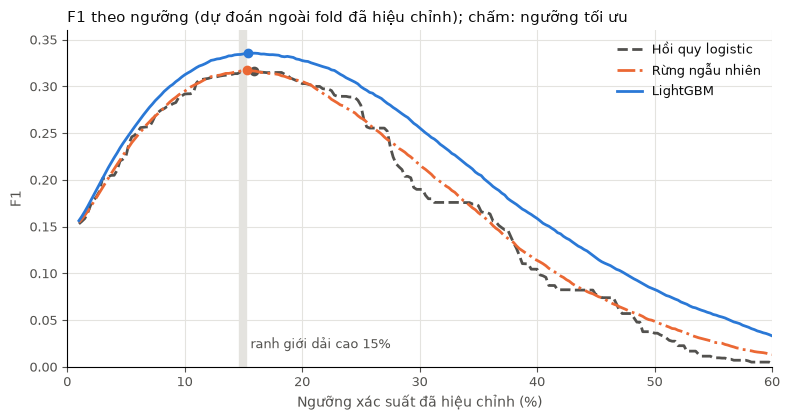

In [5]:
luoi = np.arange(0.01, 0.601, 0.0025)
fig, ax = plt.subplots(figsize=(8, 4.3))
for m, mau, ls in zip(MO_HINH, [MUTED, ORANGE, BLUE], ["--", "-.", "-"]):
    q = d[m].to_numpy()
    ax.plot(luoi * 100, [f1_score(y, q >= t) for t in luoi], color=mau, lw=2, ls=ls, label=TEN[m])
    ax.plot(chon.loc[m, "ngưỡng"] * 100, chon.loc[m, "F1"], "o", color=mau, ms=6)
ax.axvline(15, color=GRID, lw=6, zorder=0)
ax.text(15.6, 0.02, "ranh giới dải cao 15%", color=MUTED, fontsize=9)
ax.set_xlabel("Ngưỡng xác suất đã hiệu chỉnh (%)", color=MUTED)
ax.set_ylabel("F1", color=MUTED)
ax.set_xlim(0, 60)
ax.set_ylim(0, 0.36)
ax.grid(color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, labelsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9, labelcolor=INK)
ax.set_title("F1 theo ngưỡng (dự đoán ngoài fold đã hiệu chỉnh); chấm: ngưỡng tối ưu", color=INK, fontsize=11, loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "ml_nguong_f1.png", dpi=150)

In [6]:
so = []
for m in MO_HINH:
    q = d[m].to_numpy()
    for ten, t in [("tối ưu", chon.loc[m, "ngưỡng"]), ("15% (dải cao)", 0.15), ("0,5", 0.5)]:
        so.append({"mô hình": m, "ngưỡng": ten, "giá trị": t, "F1": f1_score(y, q >= t), "tỷ lệ đoán 1": (q >= t).mean()})
pd.DataFrame(so).set_index(["mô hình", "ngưỡng"])

giá trị     F1  tỷ lệ đoán 1
mô hình ngưỡng                                     
LR      tối ưu          0.1592 0.3162        0.1287
        15% (dải cao)   0.1500 0.3155        0.1530
        0,5             0.5000 0.0376        0.0030
RF      tối ưu          0.1527 0.3180        0.1411
        15% (dải cao)   0.1500 0.3172        0.1456
        0,5             0.5000 0.0488        0.0039
LGBM    tối ưu          0.1544 0.3360        0.1366
        15% (dải cao)   0.1500 0.3348        0.1427
        0,5             0.5000 0.0828        0.0067

## 4. Ma trận nhầm lẫn tại ngưỡng đã chọn (dự đoán ngoài fold)

Chỉ để mô tả trên tập train; ma trận nhầm lẫn chính thức tính trên tập test ở B11.

In [7]:
mt = []
for m in MO_HINH:
    tn, fp, fn, tp = confusion_matrix(y, d[m] >= chon.loc[m, "ngưỡng"]).ravel()
    mt.append({"mô hình": m, "TN": tn, "FP": fp, "FN": fn, "TP": tp, "precision": tp / (tp + fp), "recall": tp / (tp + fn), "tỷ lệ báo nhầm (FPR)": fp / (fp + tn)})
pd.DataFrame(mt).set_index("mô hình")

,TN,FP,FN,TP,precision,recall,tỷ lệ báo nhầm (FPR)
mô hình,,,,,,,
LR,202640,23508,11716,8144,0.2573,0.4101,0.1039
RF,200111,26037,11182,8678,0.2500,0.4370,0.1151
LGBM,201528,24620,10877,8983,0.2673,0.4523,0.1089


## 5. Lưu

In [8]:
nguong = {m: float(chon.loc[m, "ngưỡng"]) for m in MO_HINH}
(ROOT / "ml" / "data" / "nguong.json").write_text(json.dumps(nguong))
print({m: f"{t:.4%}" for m, t in nguong.items()})

{'LR': '15.9207%', 'RF': '15.2720%', 'LGBM': '15.4362%'}


## 6. Tóm tắt

- Ngưỡng của từng mô hình: `ml/data/nguong.json`, trên xác suất đã hiệu chỉnh; B11 gán nhãn 1 khi xác suất đã hiệu chỉnh ≥ ngưỡng, rồi tính F1 và ma trận nhầm lẫn trên tập test.
- Ngưỡng chỉ phục vụ đánh giá; không phải luật xét duyệt (QĐ-26 khoản 2 Điều 4).